# 23CSE301 ML Capstone — 6. Decision Tree Regressor
**Overview:** Non-parametric tree partition regressor using MSE split criteria.

**Train-Test Split:** 80:20 Ratio (`random_state=42`)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

# Load and Preprocess Data
csv_file = 'powerconsumption 2.csv' if os.path.exists('powerconsumption 2.csv') else ('data/powerconsumption.csv' if os.path.exists('data/powerconsumption.csv') else '../powerconsumption 2.csv')
df = pd.read_csv(csv_file)

df_clean = df.copy()
df_clean['Datetime'] = pd.to_datetime(df_clean['Datetime'])
df_clean['Hour'] = df_clean['Datetime'].dt.hour
df_clean['Month'] = df_clean['Datetime'].dt.month
df_clean['DayOfWeek'] = df_clean['Datetime'].dt.dayofweek
df_clean['Day'] = df_clean['Datetime'].dt.day
df_clean['IsWeekend'] = df_clean['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)
df_clean['IsNight'] = df_clean['Hour'].apply(lambda x: 1 if (x < 6 or x > 22) else 0)
df_clean['Temp_Humidity_Index'] = df_clean['Temperature'] * (df_clean['Humidity'] / 100.0)
df_clean['Total_Diffuse_Flows'] = df_clean['GeneralDiffuseFlows'] + df_clean['DiffuseFlows']

feature_cols = ['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows',
                'Hour', 'Month', 'DayOfWeek', 'Day', 'IsWeekend', 'IsNight',
                'Temp_Humidity_Index', 'Total_Diffuse_Flows']

X = df_clean[feature_cols]
y = df_clean['PowerConsumption_Zone1']

# 80:20 Split with fixed random_state=42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"Data loaded & preprocessed for 6. Decision Tree Regressor. Train: {X_train.shape[0]} rows, Test: {X_test.shape[0]} rows.")


Data loaded & preprocessed for 6. Decision Tree Regressor. Train: 41932 rows, Test: 10484 rows.


In [2]:
model = DecisionTreeRegressor(max_depth=12, random_state=42)
t0 = time.time()
model.fit(X_train, y_train)
fit_time = time.time() - t0
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"=== PERFORMANCE METRICS FOR 6. DECISION TREE REGRESSOR ===")
print(f"R2 Score:   {r2:.4f}")
print(f"RMSE (kW):  {rmse:.2f} kW")
print(f"MAE (kW):   {mae:.2f} kW")
print(f"Fit Time:   {fit_time:.3f} seconds")


=== PERFORMANCE METRICS FOR 6. DECISION TREE REGRESSOR ===
R2 Score:   0.9558
RMSE (kW):  1493.23 kW
MAE (kW):   1050.13 kW
Fit Time:   0.259 seconds


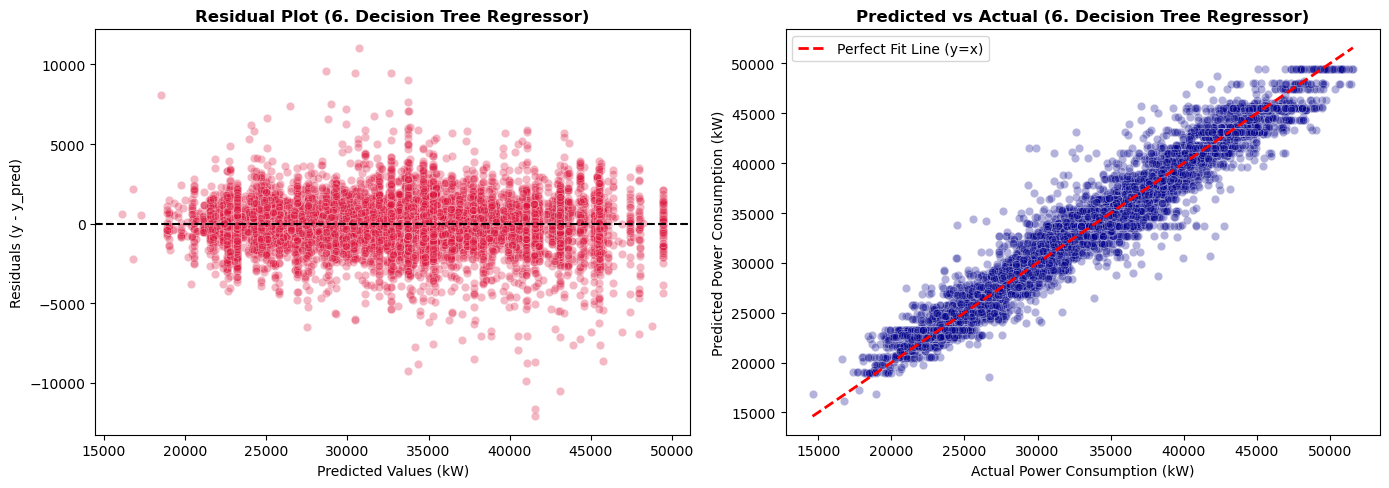

In [3]:
residuals = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=y_pred, y=residuals, ax=axes[0], alpha=0.3, color='crimson')
axes[0].axhline(y=0, color='black', linestyle='--', linewidth=1.5)
axes[0].set_title('Residual Plot', fontweight='bold')
axes[0].set_xlabel('Predicted Values (kW)')
axes[0].set_ylabel('Residuals (y - y_pred)')

sns.scatterplot(x=y_test, y=y_pred, ax=axes[1], alpha=0.3, color='darkblue')
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Fit Line (y=x)')
axes[1].set_title('Predicted vs Actual', fontweight='bold')
axes[1].set_xlabel('Actual Power Consumption (kW)')
axes[1].set_ylabel('Predicted Power Consumption (kW)')
axes[1].legend()

plt.tight_layout()
plt.show()


### Performance Summary for 6. Decision Tree Regressor
- **$R^2$ Score:** `0.9558`
- **RMSE:** `1493.23` kW
- **MAE:** `1050.13` kW
- **Fit Time:** `0.259`s
